# **Proyecto final: factores asociados al riesgo de diabetes**
Clasificación (regresión logística multinomial, Naive Bayes y SVM) y segmentación de pacientes con K-Means.

*Yago Raúl Huerta Orozco · Diplomado de Minería de Datos y Técnicas Estadísticas, Módulo 3 · FES Acatlán, UNAM*

### **0. Dependencias y carga de datos**

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.stats import chi2_contingency, kruskal
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve, silhouette_score, davies_bouldin_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Las figuras se guardan aquí y se reutilizan en el reporte en PDF
FIG_DIR = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Proyecto/Reporte_Final/figures/"
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
df = pd.read_csv("/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Data/Proyecto/diabetes_risk.csv")
print(f"{df.shape[0]:,} registros y {df.shape[1]} columnas; duplicados: {df.duplicated().sum()}; ids únicos: {df['patient_id'].is_unique}")
NIVELES = ["Low", "Moderate", "High"]            # orden natural del riesgo
df["diabetes_risk"] = pd.Categorical(df["diabetes_risk"], NIVELES, ordered=True)
faltantes = df.isna().sum()
pd.DataFrame({"faltantes": faltantes, "%": (faltantes / len(df) * 100).round(1)}).query("faltantes > 0")

15,000 registros y 19 columnas; duplicados: 0; ids únicos: True


,faltantes,%
smoking_status,472,3.1
alcohol_consumption,3788,25.3
income_bracket,463,3.1


### **1. Preprocesamiento y análisis descriptivo**

In [3]:
# ¿Los faltantes se reparten igual entre los tres niveles de riesgo?
for c in ["smoking_status", "alcohol_consumption", "income_bracket"]:
    tab = pd.crosstab(df[c].isna(), df["diabetes_risk"], normalize="columns").loc[True] * 100
    p = chi2_contingency(pd.crosstab(df[c].isna(), df["diabetes_risk"]))[1]
    print(f"{c:22s} % faltante por riesgo: {tab.round(1).to_dict()}   p = {p:.3f}")

# Los faltantes pasan a ser una categoría más
for c in ["smoking_status", "alcohol_consumption", "income_bracket"]:
    df[c] = df[c].fillna("Sin dato")

smoking_status         % faltante por riesgo: {'Low': 3.0, 'Moderate': 3.4, 'High': 3.1}   p = 0.493
alcohol_consumption    % faltante por riesgo: {'Low': 25.3, 'Moderate': 25.4, 'High': 24.7}   p = 0.814
income_bracket         % faltante por riesgo: {'Low': 3.0, 'Moderate': 2.9, 'High': 3.9}   p = 0.062


Los faltantes de alcohol, tabaquismo e ingreso se reparten igual en los tres niveles de riesgo (p > 0.05 en las tres pruebas), así que se dejan como una categoría «Sin dato» en lugar de borrar filas o imputar.

In [4]:
dist = df["diabetes_risk"].value_counts().reindex(NIVELES)
print((dist / len(df) * 100).round(1).to_string())
df.describe().T.round(2)[["mean", "std", "min", "50%", "max"]]

diabetes_risk
Low         60.0
Moderate    25.0
High        15.0


,mean,std,min,50%,max
patient_id,7500.50,4330.27,1.0,7500.5,15000.0
age,44.33,10.38,18.0,45.0,80.0
bmi,23.06,4.05,15.0,22.7,40.8
hours_sleep_per_night,7.31,1.11,3.0,7.0,12.0
stress_level,5.94,2.15,1.0,6.0,10.0
fasting_blood_sugar,168.79,38.37,72.0,165.0,400.0
hba1c_level,6.88,0.84,4.8,6.8,13.4
blood_pressure_systolic,139.50,12.66,80.0,140.0,200.0
blood_pressure_diastolic,86.26,8.39,50.0,88.0,120.0
waist_circumference_cm,100.21,10.76,73.2,99.3,148.2


La respuesta está desbalanceada: 60 % riesgo bajo, 25 % moderado y 15 % alto. Por eso más adelante se usa `class_weight="balanced"` y se miran métricas por clase, no solo la exactitud.

In [5]:
NUM = df.select_dtypes("number").columns.drop("patient_id").tolist()
CAT = [c for c in df.columns if c not in NUM + ["patient_id", "diabetes_risk"]]

filas = []
for c in NUM:        # numéricas: Kruskal-Wallis entre los tres niveles
    H, p = kruskal(*[g[c].values for _, g in df.groupby("diabetes_risk", observed=True)])
    filas.append((c, "Kruskal-Wallis", H, p))
for c in CAT:        # categóricas: chi-cuadrada
    chi, p, *_ = chi2_contingency(pd.crosstab(df[c], df["diabetes_risk"]))
    filas.append((c, "Chi-cuadrada", chi, p))
asoc = pd.DataFrame(filas, columns=["variable", "prueba", "estadístico", "p"]).sort_values("estadístico", ascending=False)
asoc["p"] = asoc["p"].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")
asoc["estadístico"] = asoc["estadístico"].round(1)
asoc.reset_index(drop=True)

,variable,prueba,estadístico,p
0,fasting_blood_sugar,Kruskal-Wallis,8072.8,<0.001
1,hba1c_level,Kruskal-Wallis,7817.1,<0.001
2,age,Kruskal-Wallis,1334.2,<0.001
3,bmi,Kruskal-Wallis,1192.6,<0.001
4,waist_circumference_cm,Kruskal-Wallis,1015.5,<0.001
5,blood_pressure_systolic,Kruskal-Wallis,694.5,<0.001
6,physical_activity_level,Chi-cuadrada,453.5,<0.001
7,blood_pressure_diastolic,Kruskal-Wallis,423.2,<0.001
8,family_history_diabetes,Chi-cuadrada,402.3,<0.001
9,stress_level,Kruskal-Wallis,162.9,<0.001


Las variables más asociadas al riesgo son la glucosa en ayunas y la HbA1c, con una distancia grande sobre el resto (le siguen edad, IMC y cintura). Entre las categóricas destacan la actividad física y los antecedentes familiares. Sexo, tipo de dieta, tabaquismo y alcohol no muestran asociación (p > 0.3).

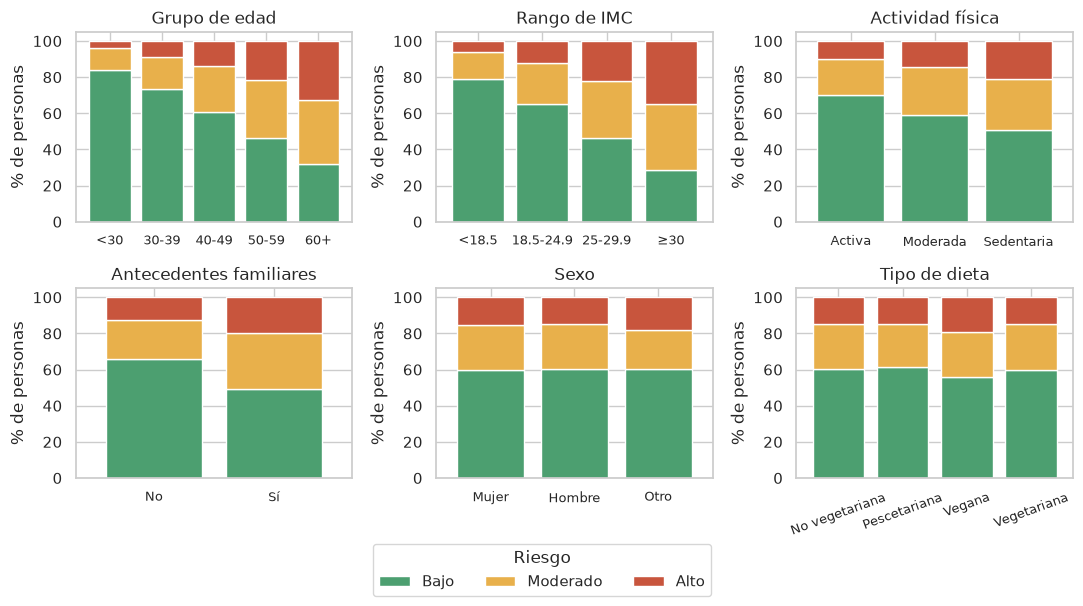

{'<30': 4.1, '30-39': 9.0, '40-49': 13.7, '50-59': 21.4, '60+': 32.4}
{'<18.5': 5.9, '18.5-24.9': 11.9, '25-29.9': 22.2, '≥30': 34.7}
{'Active': 9.8, 'Moderate': 14.4, 'Sedentary': 21.0}
{'No': 12.5, 'Yes': 19.7}


In [6]:
df["grupo_edad"] = pd.cut(df["age"], [0, 29, 39, 49, 59, 120], labels=["<30", "30-39", "40-49", "50-59", "60+"])
df["rango_imc"] = pd.cut(df["bmi"], [0, 18.5, 25, 30, 100], right=False, labels=["<18.5", "18.5-24.9", "25-29.9", "≥30"])

ES = {"Active": "Activa", "Moderate": "Moderada", "Sedentary": "Sedentaria", "No": "No", "Yes": "Sí",
      "Female": "Mujer", "Male": "Hombre", "Other": "Otro", "Non-Vegetarian": "No vegetariana",
      "Pescatarian": "Pescetariana", "Vegan": "Vegana", "Vegetarian": "Vegetariana"}
colores = {"Low": "#4c9f70", "Moderate": "#e8b04b", "High": "#c8553d"}
fig, ax = plt.subplots(2, 3, figsize=(11, 6))
for a, (col, tit) in zip(ax.ravel(), [("grupo_edad", "Grupo de edad"), ("rango_imc", "Rango de IMC"),
        ("physical_activity_level", "Actividad física"), ("family_history_diabetes", "Antecedentes familiares"),
        ("gender", "Sexo"), ("diet_type", "Tipo de dieta")]):
    t = pd.crosstab(df[col], df["diabetes_risk"], normalize="index")[NIVELES] * 100
    if col == "physical_activity_level":
        t = t.loc[["Active", "Moderate", "Sedentary"]]
    t.index = [ES.get(i, i) for i in t.index]
    t.plot(kind="bar", stacked=True, ax=a, color=[colores[n] for n in NIVELES], width=.8, legend=False)
    a.set(xlabel="", ylabel="% de personas", title=tit)
    a.tick_params(axis="x", rotation=0 if col != "diet_type" else 20, labelsize=9)
h, _ = ax[0, 0].get_legend_handles_labels()
fig.legend(h, ["Bajo", "Moderado", "Alto"], title="Riesgo", loc="lower center", ncol=3, bbox_to_anchor=(.5, -.02))
plt.tight_layout(rect=(0, .06, 1, 1))
plt.savefig(FIG_DIR + "pf_1_factores.png", dpi=150, bbox_inches="tight")
plt.show()

# % de riesgo alto por categoría, para citar en el texto
for col in ["grupo_edad", "rango_imc", "physical_activity_level", "family_history_diabetes"]:
    print((pd.crosstab(df[col], df["diabetes_risk"], normalize="index")["High"] * 100).round(1).to_dict())

El riesgo alto sube de forma clara con la edad (4.1 % en menores de 30 años contra 32.4 % en mayores de 60) y con el IMC (5.9 % con bajo peso contra 34.7 % con obesidad). Los sedentarios tienen 21.0 % de riesgo alto frente a 9.8 % de los activos, y quienes tienen antecedentes familiares 19.7 % frente a 12.5 %. Sexo y dieta casi no mueven la distribución.

               fasting_blood_sugar  hba1c_level  blood_pressure_systolic  waist_circumference_cm   bmi   age
diabetes_risk                                                                                               
Low                          148.3          6.4                    137.3                    97.9  22.1  41.9
Moderate                     183.3          7.2                    142.0                   102.7  24.1  47.3
High                         226.5          8.1                    144.0                   105.2  25.1  49.2

Correlación glucosa-HbA1c: 0.913


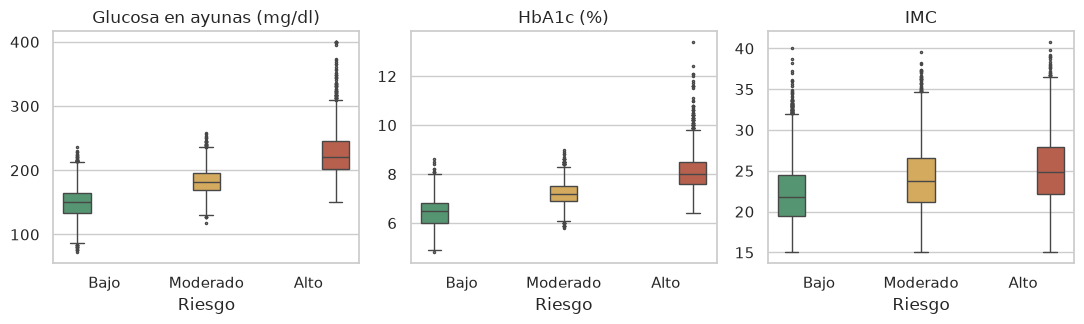

In [7]:
# Variables clínicas por nivel de riesgo
CLIN = ["fasting_blood_sugar", "hba1c_level", "blood_pressure_systolic", "waist_circumference_cm", "bmi", "age"]
print(df.groupby("diabetes_risk", observed=True)[CLIN].mean().round(1).to_string())
print("\nCorrelación glucosa-HbA1c:", df["fasting_blood_sugar"].corr(df["hba1c_level"]).round(3))
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for a, c, t in zip(ax, ["fasting_blood_sugar", "hba1c_level", "bmi"], ["Glucosa en ayunas (mg/dl)", "HbA1c (%)", "IMC"]):
    sns.boxplot(data=df, x="diabetes_risk", y=c, order=NIVELES, palette=colores, hue="diabetes_risk", legend=False, fliersize=1.5, ax=a)
    a.set(xlabel="Riesgo", ylabel="", title=t, xticks=range(3), xticklabels=["Bajo", "Moderado", "Alto"])
plt.tight_layout()
plt.savefig(FIG_DIR + "pf_1b_clinicas.png", dpi=150)
plt.show()

La glucosa media pasa de 148 mg/dl (riesgo bajo) a 226 mg/dl (alto) y la HbA1c de 6.4 % a 8.1 %, con poco traslape entre los extremos. Glucosa y HbA1c correlacionan 0.91, es decir, miden casi lo mismo; eso afecta a Naive Bayes y a la interpretación de los coeficientes.

### **2. Clasificación del nivel de riesgo**

In [8]:
y = df["diabetes_risk"].astype(str)
X = df.drop(columns=["patient_id", "diabetes_risk", "grupo_edad", "rango_imc"])
NUM = X.select_dtypes("number").columns.tolist()
CAT = [c for c in X.columns if c not in NUM]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
print(f"Entrenamiento: {len(Xtr):,} · Prueba: {len(Xte):,}")
print((ytr.value_counts(normalize=True) * 100).round(1).to_dict(), (yte.value_counts(normalize=True) * 100).round(1).to_dict())

CLAVE = ["fasting_blood_sugar", "hba1c_level"]      # glucosa en ayunas y HbA1c

def preprocesador(excluir=()):
    num = [c for c in NUM if c not in excluir]
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def modelos(excluir=(), binario=False):
    # El escalado y el one-hot viven dentro del Pipeline: se ajustan solo con entrenamiento
    mods = {"Regresión logística": LogisticRegression(max_iter=3000, class_weight="balanced"),
            "Naive Bayes": GaussianNB(),
            "SVM (RBF)": SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE)}
    return {n: Pipeline([("prep", preprocesador(excluir)), ("m", m)]) for n, m in mods.items()}

Entrenamiento: 10,500 · Prueba: 4,500
{'Low': 60.0, 'Moderate': 25.0, 'High': 15.0} {'Low': 60.0, 'Moderate': 25.0, 'High': 15.0}


In [9]:
ESCENARIOS = {"Con glucosa y HbA1c": (), "Sin glucosa ni HbA1c": tuple(CLAVE)}
ajustados, metricas = {}, []
for esc, excl in ESCENARIOS.items():
    for nombre, pipe in modelos(excl).items():
        pipe.fit(Xtr.drop(columns=list(excl)), ytr)
        Xt = Xte.drop(columns=list(excl))
        pred, prob = pipe.predict(Xt), pipe.predict_proba(Xt)
        ajustados[(esc, nombre)] = pipe
        metricas.append({"Escenario": esc, "Modelo": nombre,
                         "Exactitud": accuracy_score(yte, pred),
                         "Precisión (macro)": precision_score(yte, pred, average="macro"),
                         "Sensibilidad (macro)": recall_score(yte, pred, average="macro"),
                         "F1 (macro)": f1_score(yte, pred, average="macro"),
                         "AUC (OvR)": roc_auc_score(yte, prob, multi_class="ovr", labels=pipe.classes_)})
metricas = pd.DataFrame(metricas)
metricas.round(3)

,Escenario,Modelo,Exactitud,Precisión (macro),Sensibilidad (macro),F1 (macro),AUC (OvR)
0,Con glucosa y HbA1c,Regresión logística,0.761,0.721,0.746,0.729,0.906
1,Con glucosa y HbA1c,Naive Bayes,0.720,0.667,0.681,0.669,0.867
2,Con glucosa y HbA1c,SVM (RBF),0.750,0.717,0.735,0.721,0.905
3,Sin glucosa ni HbA1c,Regresión logística,0.520,0.447,0.472,0.443,0.691
4,Sin glucosa ni HbA1c,Naive Bayes,0.526,0.428,0.434,0.430,0.645
5,Sin glucosa ni HbA1c,SVM (RBF),0.527,0.450,0.467,0.449,0.688


Con todas las variables, la regresión logística y la SVM quedan prácticamente empatadas (exactitud 0.76 y 0.75, AUC 0.91) y Naive Bayes es el más débil (0.72 y 0.87). **Sin glucosa ni HbA1c los tres modelos se desploman a una exactitud de ~0.52 y un AUC de 0.65-0.69.** Casi todo el poder predictivo está en esas dos mediciones.

In [10]:
# Validación cruzada estratificada de 5 pliegues sobre todos los datos
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
filas = []
for esc, excl in ESCENARIOS.items():
    for nombre, pipe in modelos(excl).items():
        r = cross_validate(pipe, X.drop(columns=list(excl)), y, cv=skf, n_jobs=-1,
                           scoring={"acc": "accuracy", "f1": "f1_macro", "auc": "roc_auc_ovr"})
        filas.append({"Escenario": esc, "Modelo": nombre,
                      "Exactitud": f"{r['test_acc'].mean():.3f} ± {r['test_acc'].std():.3f}",
                      "F1 (macro)": f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
                      "AUC (OvR)": f"{r['test_auc'].mean():.3f} ± {r['test_auc'].std():.3f}"})
pd.DataFrame(filas)

,Escenario,Modelo,Exactitud,F1 (macro),AUC (OvR)
0,Con glucosa y HbA1c,Regresión logística,0.768 ± 0.007,0.738 ± 0.007,0.911 ± 0.002
1,Con glucosa y HbA1c,Naive Bayes,0.733 ± 0.009,0.689 ± 0.012,0.874 ± 0.006
2,Con glucosa y HbA1c,SVM (RBF),0.762 ± 0.006,0.733 ± 0.006,0.913 ± 0.002
3,Sin glucosa ni HbA1c,Regresión logística,0.523 ± 0.014,0.442 ± 0.014,0.695 ± 0.008
4,Sin glucosa ni HbA1c,Naive Bayes,0.541 ± 0.011,0.438 ± 0.011,0.645 ± 0.011
5,Sin glucosa ni HbA1c,SVM (RBF),0.531 ± 0.012,0.452 ± 0.010,0.692 ± 0.006


La validación cruzada confirma lo anterior con desviaciones pequeñas (≤ 0.014): el orden de los modelos no depende de la partición. Naive Bayes sale peor con glucosa y HbA1c, lo esperable al violar su supuesto de independencia con dos variables correlacionadas en 0.91.

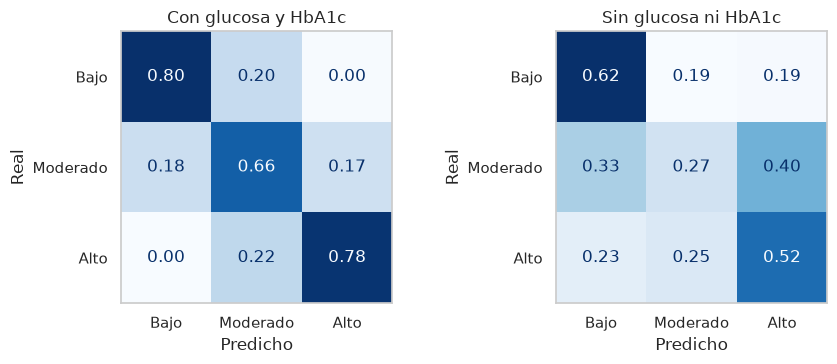

In [11]:
# Matrices de confusión de la regresión logística (conjunto de prueba)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, esc in zip(ax, ESCENARIOS):
    pipe = ajustados[(esc, "Regresión logística")]
    Xt = Xte.drop(columns=list(ESCENARIOS[esc]))
    ConfusionMatrixDisplay.from_predictions(yte, pipe.predict(Xt), labels=NIVELES, display_labels=["Bajo", "Moderado", "Alto"],
                                            cmap="Blues", colorbar=False, normalize="true", values_format=".2f", ax=a)
    a.set(title=esc, xlabel="Predicho", ylabel="Real"); a.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR + "pf_2_confusion.png", dpi=150)
plt.show()

Con glucosa y HbA1c los errores son casi siempre a la clase vecina: nunca se confunde bajo con alto (0.00). Sin ellas el modelo se pierde: solo acierta 27 % de los moderados y confunde bajo con alto en 19 % de los casos.

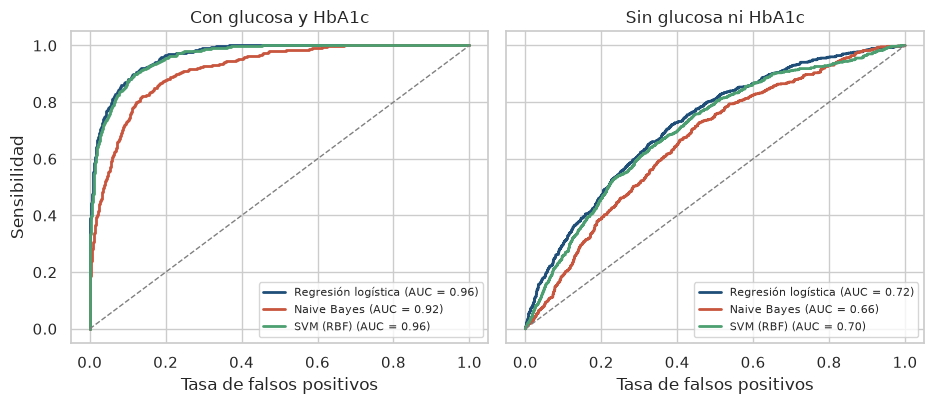

In [12]:
# Curvas ROC de la clase "riesgo alto" (uno contra el resto), tres modelos
colmod = {"Regresión logística": "#1f4e79", "Naive Bayes": "#c8553d", "SVM (RBF)": "#4c9f70"}
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.2), sharey=True)
for a, (esc, excl) in zip(ax, ESCENARIOS.items()):
    for nombre in colmod:
        pipe = ajustados[(esc, nombre)]
        prob = pipe.predict_proba(Xte.drop(columns=list(excl)))[:, list(pipe.classes_).index("High")]
        fpr, tpr, _ = roc_curve(yte == "High", prob)
        a.plot(fpr, tpr, color=colmod[nombre], lw=2, label=f"{nombre} (AUC = {roc_auc_score(yte == 'High', prob):.2f})")
    a.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    a.set(title=esc, xlabel="Tasa de falsos positivos", ylabel="Sensibilidad" if a is ax[0] else "")
    a.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR + "pf_3_roc.png", dpi=150)
plt.show()

Con las dos mediciones clínicas la curva de la clase «riesgo alto» llega a AUC 0.96 en la logística y la SVM (0.92 en Naive Bayes). Sin ellas baja a 0.72, 0.70 y 0.66: sigue por encima del azar, pero ya no sirve como herramienta de detección.

In [13]:
# Versión binaria: riesgo alto frente al resto
yb_tr, yb_te = (ytr == "High").astype(int), (yte == "High").astype(int)
filas = []
for esc, excl in ESCENARIOS.items():
    for nombre, pipe in modelos(excl).items():
        pipe.fit(Xtr.drop(columns=list(excl)), yb_tr)
        Xt = Xte.drop(columns=list(excl))
        pred, prob = pipe.predict(Xt), pipe.predict_proba(Xt)[:, 1]
        filas.append({"Escenario": esc, "Modelo": nombre, "Exactitud": accuracy_score(yb_te, pred),
                      "Precisión": precision_score(yb_te, pred), "Sensibilidad": recall_score(yb_te, pred),
                      "F1": f1_score(yb_te, pred), "AUC": roc_auc_score(yb_te, prob)})
pd.DataFrame(filas).round(3)

,Escenario,Modelo,Exactitud,Precisión,Sensibilidad,F1,AUC
0,Con glucosa y HbA1c,Regresión logística,0.891,0.593,0.879,0.708,0.964
1,Con glucosa y HbA1c,Naive Bayes,0.880,0.575,0.770,0.658,0.925
2,Con glucosa y HbA1c,SVM (RBF),0.889,0.589,0.865,0.701,0.956
3,Sin glucosa ni HbA1c,Regresión logística,0.658,0.257,0.680,0.373,0.724
4,Sin glucosa ni HbA1c,Naive Bayes,0.750,0.261,0.364,0.304,0.670
5,Sin glucosa ni HbA1c,SVM (RBF),0.675,0.255,0.609,0.360,0.690


En la versión binaria (alto contra el resto) el patrón es el mismo: con glucosa y HbA1c la logística logra AUC 0.96, sensibilidad 0.88 y precisión 0.59; sin ellas el AUC baja a 0.72 y la precisión a 0.26: de cada cuatro alertas, tres son falsas.

In [14]:
# Razones de momios (por 1 desviación estándar en numéricas) de la regresión logística binaria, riesgo alto vs resto
def razones_momios(excluir=()):
    prep = preprocesador(excluir)
    A = prep.fit_transform(Xtr.drop(columns=list(excluir)))
    lr = LogisticRegression(max_iter=3000, C=1e6).fit(A, yb_tr)      # casi sin regularizar
    nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    return pd.Series(np.exp(lr.coef_[0]), index=nombres)

orr = {esc: razones_momios(excl) for esc, excl in ESCENARIOS.items()}
for esc, s in orr.items():
    print(esc); print(s.sort_values(ascending=False).head(8).round(2).to_string()); print()
print("Sin glucosa ni HbA1c, los de menor razón:"); print(orr["Sin glucosa ni HbA1c"].sort_values().head(5).round(2).to_string())

Con glucosa y HbA1c
fasting_blood_sugar       9.26
hba1c_level               5.65
age                       2.16
bmi                       1.59
city_Bhopal               1.53
city_Visakhapatnam        1.25
waist_circumference_cm    1.12
city_Chennai              1.11

Sin glucosa ni HbA1c
age                   1.67
bmi                   1.56
city_Bhopal           1.35
city_Visakhapatnam    1.26
city_Jaipur           1.21
stress_level          1.17
diet_type_Vegan       1.16
city_Surat            1.12

Sin glucosa ni HbA1c, los de menor razón:
family_history_diabetes_No    0.59
city_Kolkata                  0.69
gender_Male                   0.77
income_bracket_Middle         0.78
city_Indore                   0.78


Con glucosa y HbA1c, un aumento de una desviación estándar en glucosa multiplica los momios de riesgo alto por 9.3 y en HbA1c por 5.7. Sin esas dos, lo que más pesa es la edad (1.67 por desviación estándar) y el IMC (1.56); no tener antecedentes familiares tiene razón 0.59, es decir, tenerlos equivale a ~1.7 veces los momios. Las razones por ciudad son pequeñas y cercanas a 1; Bhopal destaca (1.35-1.53) pero con efecto modesto.

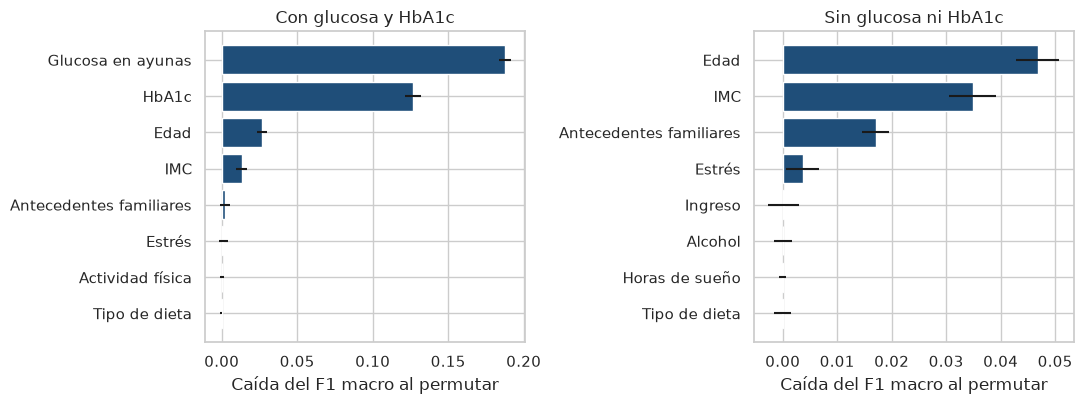

Con glucosa y HbA1c {'fasting_blood_sugar': 0.188, 'hba1c_level': 0.127, 'age': 0.027, 'bmi': 0.013, 'family_history_diabetes': 0.002, 'stress_level': 0.001}
Sin glucosa ni HbA1c {'age': 0.047, 'bmi': 0.035, 'family_history_diabetes': 0.017, 'stress_level': 0.004, 'income_bracket': 0.0, 'alcohol_consumption': 0.0}


In [15]:
# Importancia por permutación (regresión logística multinomial, conjunto de prueba, F1 macro)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
perm = {}
ES_VAR = {"fasting_blood_sugar": "Glucosa en ayunas", "hba1c_level": "HbA1c", "age": "Edad", "bmi": "IMC",
          "family_history_diabetes": "Antecedentes familiares", "stress_level": "Estrés", "physical_activity_level": "Actividad física",
          "diet_type": "Tipo de dieta", "income_bracket": "Ingreso", "alcohol_consumption": "Alcohol",
          "hours_sleep_per_night": "Horas de sueño"}
for a, (esc, excl) in zip(ax, ESCENARIOS.items()):
    pipe, Xt = ajustados[(esc, "Regresión logística")], Xte.drop(columns=list(excl))
    r = permutation_importance(pipe, Xt, yte, scoring="f1_macro", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=Xt.columns).sort_values(ascending=False)
    perm[esc] = imp
    top = imp.head(8)[::-1]
    a.barh([ES_VAR.get(i, i) for i in top.index], top.values, xerr=pd.Series(r.importances_std, index=Xt.columns)[top.index], color="#1f4e79")
    a.set(title=esc, xlabel="Caída del F1 macro al permutar")
plt.tight_layout()
plt.savefig(FIG_DIR + "pf_4_permutacion.png", dpi=150)
plt.show()
for esc, imp in perm.items():
    print(esc, imp.head(6).round(3).to_dict())

La importancia por permutación coincide con las razones de momios. Con todas las variables dominan la glucosa (0.19) y la HbA1c (0.13), seguidas de edad (0.03) y IMC (0.01). Sin ellas, edad (0.05), IMC (0.03) y antecedentes familiares (0.02) pasan a ser lo más útil. La actividad física importa poco una vez que se controla por IMC y edad, aunque sola sí se asocia con el riesgo.

### **3. K-Means: perfiles de pacientes**

In [16]:
# Seis variables clínicas; no se usa la etiqueta de riesgo
VARS_KM = ["age", "bmi", "fasting_blood_sugar", "hba1c_level", "blood_pressure_systolic", "waist_circumference_cm"]
Z = StandardScaler().fit_transform(df[VARS_KM])

ks = range(2, 9)
inercia, sil = [], []
for k in ks:
    m = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inercia.append(m.inertia_); sil.append(silhouette_score(Z, m.labels_))
pd.DataFrame({"k": list(ks), "inercia": np.round(inercia), "silhouette": np.round(sil, 3)}).set_index("k").T

k,2,3,4,5,6,7,8
inercia,63493.000,53891.000,47016.000,42683.00,39074.000,36302.00,34466.000
silhouette,0.257,0.235,0.195,0.19,0.188,0.18,0.171


La inercia baja sin un codo claro. La silhouette es máxima en k = 2 (0.26) y cae a 0.20 en k = 4, es decir, los datos forman un continuo más que grupos separados. Se elige k = 4 porque es el menor número de grupos que separa perfiles clínicamente distintos (ver abajo) y k = 2 sería una división demasiado gruesa.

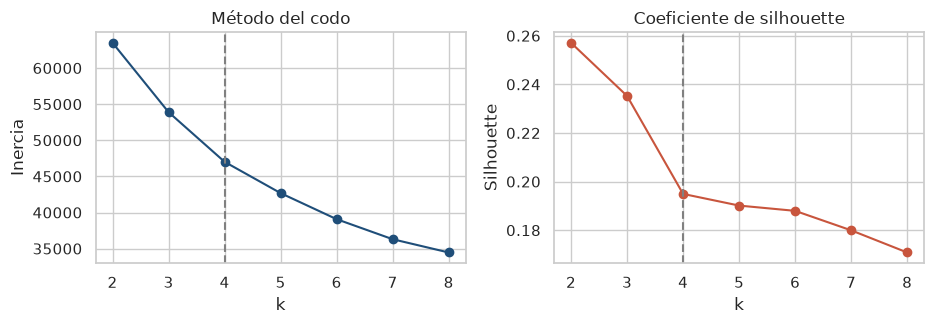

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax[0].plot(list(ks), inercia, "o-", color="#1f4e79"); ax[0].axvline(4, ls="--", color="gray")
ax[0].set(xlabel="k", ylabel="Inercia", title="Método del codo")
ax[1].plot(list(ks), sil, "o-", color="#c8553d"); ax[1].axvline(4, ls="--", color="gray")
ax[1].set(xlabel="k", ylabel="Silhouette", title="Coeficiente de silhouette")
plt.tight_layout()
plt.savefig(FIG_DIR + "pf_5_codo.png", dpi=150)
plt.show()

El codo es suave: la inercia sigue bajando en cada k. Se marca k = 4 como compromiso entre interpretabilidad y silhouette.

In [18]:
K = 4
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z)
df["grupo"] = km.labels_ + 1          # grupos numerados del 1 al 4
print(f"k = {K}: silhouette {silhouette_score(Z, km.labels_):.3f} · Davies-Bouldin {davies_bouldin_score(Z, km.labels_):.2f}")

perfil = df.groupby("grupo")[VARS_KM].mean().round(1)
perfil.insert(0, "n", df["grupo"].value_counts().sort_index())
perfil.insert(1, "%", (perfil["n"] / len(df) * 100).round(1))
riesgo_g = (pd.crosstab(df["grupo"], df["diabetes_risk"], normalize="index")[NIVELES] * 100).round(1)
habitos = df.groupby("grupo").agg(sedentario=("physical_activity_level", lambda s: (s == "Sedentary").mean() * 100),
                                  antecedentes=("family_history_diabetes", lambda s: (s == "Yes").mean() * 100)).round(1)
pd.concat([perfil, riesgo_g.add_prefix("% riesgo "), habitos.add_prefix("% ")], axis=1)

k = 4: silhouette 0.195 · Davies-Bouldin 1.43


,n,%,age,bmi,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,waist_circumference_cm,% riesgo Low,% riesgo Moderate,% riesgo High,% sedentario,% antecedentes
grupo,,,,,,,,,,,,,
1,4370,29.1,34.6,20.5,141.2,6.3,128.6,93.5,91.5,8.2,0.3,16.2,30.3
2,4836,32.2,50.0,21.7,160.2,6.7,143.7,96.5,69.9,26.8,3.3,26.7,34.2
3,2235,14.9,45.5,22.9,228.0,8.2,139.9,99.6,5.3,32.4,62.3,32.9,43.9
4,3559,23.7,47.8,28.3,177.2,7.0,147.0,113.9,42.2,38.6,19.3,62.2,36.1


Los grupos, con 6 variables clínicas y sin usar la etiqueta, se alinean bien con el riesgo:

1. **Jóvenes sin alteraciones** (29.1 %): edad 34.6, IMC 20.5, glucosa 141; 91.5 % de riesgo bajo.
2. **Mayores con presión elevada** (32.2 %): edad 50.0, sistólica 144, valores metabólicos casi promedio; 69.9 % bajo.
3. **Glucemia alta** (14.9 %): glucosa 228, HbA1c 8.2; **62.3 % de riesgo alto** y solo 5.3 % bajo.
4. **Obesidad abdominal** (23.7 %): IMC 28.3, cintura 114 cm, presión 147; 62.2 % sedentarios; riesgo repartido (42.2 % bajo, 38.6 % moderado, 19.3 % alto).

La silhouette de 0.195 y un Davies-Bouldin de 1.43 indican grupos que se tocan: son perfiles tendenciales, no clases cerradas.

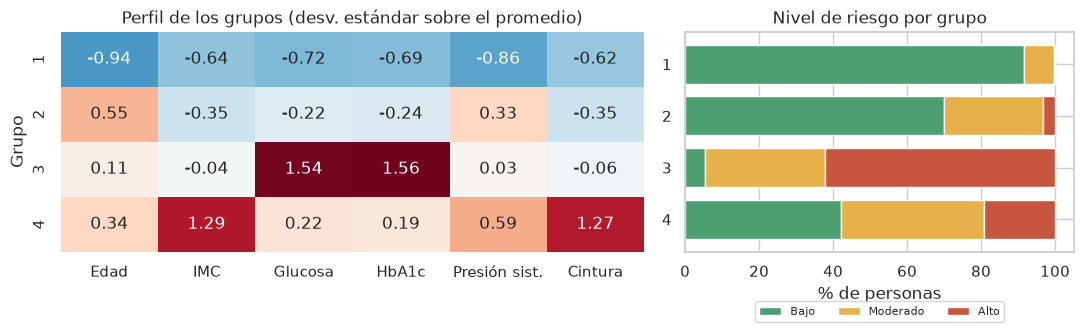

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
prof = pd.DataFrame(Z, columns=VARS_KM).groupby(df["grupo"].values).mean()
prof.columns = ["Edad", "IMC", "Glucosa", "HbA1c", "Presión sist.", "Cintura"]
sns.heatmap(prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.6, vmax=1.6, cbar=False, ax=ax[0])
ax[0].set(xlabel="", ylabel="Grupo", title="Perfil de los grupos (desv. estándar sobre el promedio)")
riesgo_g.rename(columns={"Low": "Bajo", "Moderate": "Moderado", "High": "Alto"}).plot(kind="barh", stacked=True, color=[colores[n] for n in NIVELES], ax=ax[1], legend=False, width=.75)
ax[1].set(xlabel="% de personas", ylabel="", title="Nivel de riesgo por grupo"); ax[1].invert_yaxis()
ax[1].legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.2), title=None)
plt.tight_layout()
plt.savefig(FIG_DIR + "pf_6_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

El mapa de calor muestra que el grupo 3 se distingue casi solo por glucosa y HbA1c (+1.5 desviaciones estándar) y el grupo 4 por IMC y cintura (+1.3). El grupo 1 está por debajo del promedio en todo. La barra de la derecha confirma que el riesgo sube del grupo 1 al 3.

Varianza explicada: [0.46  0.245] → 0.705


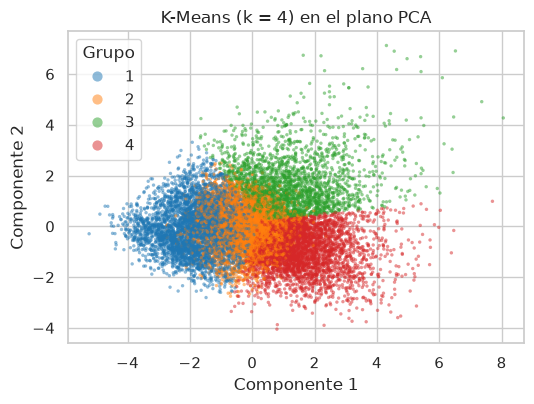

In [20]:
pca = PCA(2, random_state=RANDOM_STATE).fit(Z)
P = pca.transform(Z)
print("Varianza explicada:", pca.explained_variance_ratio_.round(3), "→", pca.explained_variance_ratio_.sum().round(3))
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["grupo"].values, palette="tab10", s=6, alpha=.5, linewidth=0, ax=ax)
ax.set(xlabel="Componente 1", ylabel="Componente 2", title=f"K-Means (k = {K}) en el plano PCA")
ax.legend(title="Grupo", markerscale=3)
plt.tight_layout()
plt.savefig(FIG_DIR + "pf_7_pca.png", dpi=150)
plt.show()

Los dos primeros componentes explican 70.5 % de la varianza. El grupo 1 queda a la izquierda, el 3 (glucemia alta) arriba y el 4 (obesidad abdominal) abajo a la derecha; el 2 queda en el centro, pegado a los demás. Las fronteras se ven continuas, de acuerdo con la silhouette baja.

### **4. Cierre**

- La **regresión logística** y la **SVM** rinden igual (AUC 0.91 con todas las variables) y la logística es la más fácil de interpretar; **Naive Bayes** queda atrás por la correlación glucosa-HbA1c.
- Casi todo el poder predictivo viene de la **glucosa en ayunas y la HbA1c**. Sin ellas el AUC baja a ~0.69; lo que queda es edad, IMC y antecedentes familiares.
- **K-Means** con k = 4 encuentra cuatro perfiles clínicos que se alinean con el riesgo, aunque con grupos que se traslapan (silhouette 0.195).
- Limitaciones: datos **sintéticos** y observacionales (asociación, no causalidad); la etiqueta parece construida a partir de glucosa y HbA1c, por lo que el desempeño con ellas puede ser optimista; faltantes de alcohol (25 %) tratados como categoría.